# Problem 3
By using *Google Colaboratory* (https://colab.research.google.com/) or otherwise, use *Pytorch* to specify the feedforward neural network architecture:
$$
\mathscr
{N}_3(3,20,15,1;\mathrm{Id},\mathrm{ReLU},\mathrm{ReLU}),
$$
Inspect the architecture and compute the number of parameters. Can you get the same result by a manual calculation?
Finally, visualise $x \mapsto f(x,2,-1)$ on $[-1,1]$ for $f$ with the above architecture and randomly initialized weights.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [2]:
# neural network architecture
f = nn.Sequential(
    nn.Linear(3, 20),
    nn.Identity(),
    nn.Linear(20, 15),
    nn.ReLU(),
    nn.Linear(15, 1),
    nn.ReLU()
)

# number of parameters
total_params = sum(p.numel() for p in f.parameters())
print(f"Total params: {total_params}")

Total params: 411


### Number of paramters by manual calculation
First layer: $20\times(3+1) = 80$,<br>
Second layer: $15\times(20+1)=315$,<br>
Third layer: $1\times(15+1)=16$,<br>
Total: $80+315+16=411$.

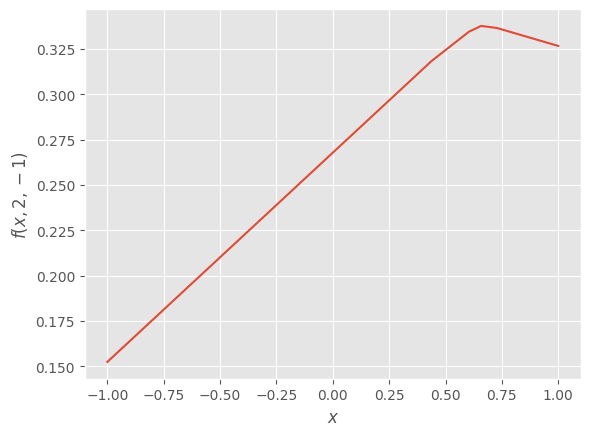

In [3]:
x_grid = np.linspace(-1, 1, 1001)
x = np.column_stack((x_grid, 2*np.ones_like(x_grid), -np.ones_like(x_grid)))
x_tensor = torch.from_numpy(x).float()

with torch.no_grad():
    y_tensor = f(x_tensor)
y_grid = y_tensor.numpy()

plt.plot(x_grid, y_grid)
plt.xlabel(r"$x$")
plt.ylabel(r"$f(x,2,-1)$")
plt.show()